# 04 · RAG context selection as a QUBO: QAOA vs greedy vs annealing

**QGAI open notebooks · Track: Quantum RAG Systems**

A retrieval-augmented generation (RAG) system must choose which retrieved passages go into the prompt. The usual answer, the
**top-k most similar passages**, often picks near-duplicates and misses complementary evidence.

Choosing a *set* of passages that is relevant **and** non-redundant is a combinatorial optimisation problem. Written as a
**QUBO** (quadratic unconstrained binary optimisation), it becomes the native input of quantum optimisers (QAOA) and annealers.

We compare five selectors on a small, hand-written corpus:

| Selector | Type |
|---|---|
| Top-k by relevance | classical greedy (the common default) |
| MMR (maximal marginal relevance) | classical greedy with a diversity term |
| Simulated annealing on the QUBO | classical heuristic |
| QAOA on the QUBO, depth p = 1, 2, 3 | quantum (simulated) |
| Exhaustive search on the QUBO | classical exact (possible because n = 10) |

Each passage is labelled with the **aspect** of the question it answers, so we can check which selections actually cover the question.

In [1]:
import itertools, time
import numpy as np
import pennylane as qml
from pennylane import numpy as pnp
import re
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt

SEED = 5
rng = np.random.default_rng(SEED)

## The corpus
Three passages say almost the same thing about error correction. Others cover noise and mitigation, and some are distractors or off-topic.
Relevance is TF-IDF cosine similarity, a deliberately simple stand-in for a real embedding model.

In [2]:
query = "How do quantum computers deal with errors and noise?"
corpus = [
    ("Quantum computers deal with errors through error correction, which encodes one logical qubit in many physical qubits so errors can be detected and fixed.", "error correction"),
    ("To deal with errors, quantum computers use error correction: a logical qubit is spread over many physical qubits so errors can be found and fixed.", "error correction"),
    ("Quantum error correction lets quantum computers handle errors by building each logical qubit from many physical qubits and correcting errors as they appear.", "error correction"),
    ("Noise from heat and stray electromagnetic fields makes qubits lose their quantum state, a process called decoherence.", "noise"),
    ("Qubits are fragile: environmental noise causes decoherence, so quantum information fades within microseconds to seconds.", "noise"),
    ("Before full error correction is available, error mitigation such as zero-noise extrapolation estimates and removes the effect of noise on results.", "mitigation"),
    ("Classical computers also correct errors, using codes such as Hamming codes in memory and networks.", "distractor"),
    ("Simulating molecules could one day speed up drug discovery.", "off-topic"),
    ("Superconducting qubits are cooled to near absolute zero inside dilution refrigerators.", "off-topic"),
    ("Surface codes are a leading error correction scheme that detects errors through repeated parity checks on neighbouring qubits.", "error correction"),
]
texts = [c[0] for c in corpus]; aspects = [c[1] for c in corpus]
n = len(corpus); K = 3
USEFUL = {"error correction", "noise", "mitigation"}

def analyzer(doc):
    """Lower-case words, drop stop words, and strip a plural 's' so 'errors' matches 'error'."""
    toks = re.findall(r"[a-z]+", doc.lower())
    return [t[:-1] if len(t) > 3 and t.endswith("s") and not t.endswith("ss") else t for t in toks if t not in ENGLISH_STOP_WORDS]

vec = TfidfVectorizer(analyzer=analyzer).fit(texts + [query])
P = vec.transform(texts); Q = vec.transform([query])
rel = cosine_similarity(P, Q).ravel()            # relevance to the query
sim = cosine_similarity(P); np.fill_diagonal(sim, 0)   # passage-passage similarity
for i in np.argsort(-rel):
    print(f"[{i}] rel={rel[i]:.2f}  {aspects[i]:16s} {texts[i][:70]}…")

[0] rel=0.48  error correction Quantum computers deal with errors through error correction, which enc…
[1] rel=0.48  error correction To deal with errors, quantum computers use error correction: a logical…
[2] rel=0.37  error correction Quantum error correction lets quantum computers handle errors by build…
[5] rel=0.31  mitigation       Before full error correction is available, error mitigation such as ze…
[4] rel=0.18  noise            Qubits are fragile: environmental noise causes decoherence, so quantum…
[3] rel=0.17  noise            Noise from heat and stray electromagnetic fields makes qubits lose the…
[6] rel=0.14  distractor       Classical computers also correct errors, using codes such as Hamming c…
[9] rel=0.11  error correction Surface codes are a leading error correction scheme that detects error…
[7] rel=0.00  off-topic        Simulating molecules could one day speed up drug discovery.…
[8] rel=0.00  off-topic        Superconducting qubits are cooled to near absolute ze

## The QUBO
Binary $x_i = 1$ if passage $i$ is selected. Minimise
$$E(x) = -\sum_i r_i x_i \; + \; \lambda \sum_{i<j} s_{ij} x_i x_j \; + \; \mu \Big(\sum_i x_i - K\Big)^2$$
Relevance is rewarded, redundancy penalised, and the last term asks for exactly $K = 3$ passages.

In [3]:
LAM, MU = 0.6, 1.0   # redundancy weight and "exactly K" penalty
Qm = np.zeros((n, n))
for i in range(n):
    Qm[i, i] = -rel[i] + MU * (1 - 2 * K)
for i, j in itertools.combinations(range(n), 2):
    Qm[i, j] = LAM * sim[i, j] + 2 * MU
CONST = MU * K * K

def energy(x):
    x = np.asarray(x)
    return float(x @ np.diag(Qm) + sum(Qm[i, j] * x[i] * x[j] for i, j in itertools.combinations(range(n), 2)) + CONST)

def describe(sel):
    x = np.zeros(n, int); x[list(sel)] = 1
    covered = {aspects[i] for i in sel} & USEFUL
    return dict(sel=sorted(int(i) for i in sel), energy=energy(x), relevance=float(rel[list(sel)].sum()),
                redundancy=float(sum(sim[i, j] for i, j in itertools.combinations(sel, 2))), aspects=len(covered))

all_x = np.array(list(itertools.product([0, 1], repeat=n)))
energies = np.array([energy(x) for x in all_x])
best = all_x[np.argmin(energies)]
results = {}

## Classical selectors

In [4]:
results["Top-3 by relevance"] = describe(np.argsort(-rel)[:K])

def mmr(lmb=0.5):
    chosen = []
    while len(chosen) < K:
        cand = [i for i in range(n) if i not in chosen]
        score = [lmb * rel[i] - (1 - lmb) * max([sim[i, j] for j in chosen], default=0) for i in cand]
        chosen.append(cand[int(np.argmax(score))])
    return chosen
results["MMR (λ = 0.5)"] = describe(mmr())

def simulated_annealing(steps=4000, restarts=20):
    best_x, best_e = None, np.inf
    for _ in range(restarts):
        x = rng.integers(0, 2, n); e = energy(x)
        for t in range(steps):
            T = 2.0 * (1 - t / steps) + 1e-3
            y = x.copy(); y[rng.integers(n)] ^= 1; ey = energy(y)
            if ey < e or rng.random() < np.exp((e - ey) / T):
                x, e = y, ey
        if e < best_e: best_x, best_e = x.copy(), e
    return np.flatnonzero(best_x)
t = time.time(); results["Simulated annealing"] = describe(simulated_annealing()); print(f"annealing: {time.time() - t:.1f}s")
results["Exhaustive (exact optimum)"] = describe(np.flatnonzero(best))

annealing: 1.5s


## QAOA
Substituting $x_i = (1 - z_i)/2$ turns the QUBO into an Ising Hamiltonian. QAOA alternates *cost* and *mixer* layers $p$ times,
with angles trained to minimise the expected energy. We then look at the probability of measuring the optimal selection.

In [5]:
h = np.zeros(n); J = {}
for i in range(n):
    h[i] -= Qm[i, i] / 2
for i, j in itertools.combinations(range(n), 2):
    J[(i, j)] = Qm[i, j] / 4
    h[i] -= Qm[i, j] / 4; h[j] -= Qm[i, j] / 4
offset = CONST + np.diag(Qm).sum() / 2 + sum(Qm[i, j] for i, j in itertools.combinations(range(n), 2)) / 4
coeffs = list(h) + list(J.values())
ops = [qml.PauliZ(i) for i in range(n)] + [qml.PauliZ(i) @ qml.PauliZ(j) for i, j in J]
H = qml.Hamiltonian(coeffs, ops)

# sanity check: the Ising energies equal the QUBO energies for every bitstring
z = 1 - 2 * all_x
ising = z @ h + sum(c * z[:, i] * z[:, j] for (i, j), c in J.items()) + offset
assert np.allclose(ising, energies), "QUBO -> Ising mapping is wrong"
print("QUBO -> Ising mapping verified on all", len(all_x), "bitstrings")

dev = qml.device("default.qubit", wires=n)
def qaoa_layers(params, p):
    for w in range(n): qml.Hadamard(w)
    for k in range(p):
        qml.qaoa.cost_layer(params[k, 0], H)
        qml.qaoa.mixer_layer(params[k, 1], qml.qaoa.x_mixer(range(n)))

@qml.qnode(dev, diff_method="backprop")
def qaoa_energy(params, p): qaoa_layers(params, p); return qml.expval(H)

@qml.qnode(dev)
def qaoa_probs(params, p): qaoa_layers(params, p); return qml.probs(wires=range(n))

opt_index = int("".join(map(str, best)), 2)
qaoa_stats, prev = {}, None
for p in [1, 2, 3]:
    # Starting points: random angles, plus a warm start that extends the best depth-(p-1) solution
    starts = [np.column_stack([rng.uniform(0, 1.0, p), rng.uniform(0, np.pi / 2, p)]) for _ in range(3)]
    if prev is not None:
        starts.append(np.vstack([prev, [[0.05, 0.05]]]))
    best_run = None
    for st in starts:
        params = pnp.array(st, requires_grad=True)
        opt = qml.AdamOptimizer(0.05)
        for _ in range(150):
            params = opt.step(lambda a: qaoa_energy(a, p), params)
        e_final = float(qaoa_energy(params, p)) + offset   # H omits the constant offset; add it back
        if best_run is None or e_final < best_run[1]: best_run = (np.array(params), e_final)
    prev = best_run[0]
    probs = np.asarray(qaoa_probs(best_run[0], p))
    shots = rng.choice(len(probs), size=100, p=probs / probs.sum())
    best_shot = all_x[shots[np.argmin(energies[shots])]]
    qaoa_stats[p] = dict(p_opt=probs[opt_index], exp_e=best_run[1])
    results[f"QAOA p={p} (best of 100 shots)"] = describe(np.flatnonzero(best_shot))
    print(f"p={p}: expected energy {best_run[1]:.3f} (optimum {energies.min():.3f}, average over all selections {energies.mean():.3f}), "
          f"P(optimal) = {probs[opt_index]:.4f} ({probs[opt_index] * 2 ** n:.1f}x random), P(optimal within 100 shots) = {1 - (1 - probs[opt_index]) ** 100:.0%}")

QUBO -> Ising mapping verified on all 1024 bitstrings


p=1: expected energy 0.400 (optimum -0.747, average over all selections 6.162), P(optimal) = 0.0039 (4.0x random), P(optimal within 100 shots) = 33%


p=2: expected energy -0.005 (optimum -0.747, average over all selections 6.162), P(optimal) = 0.0056 (5.7x random), P(optimal within 100 shots) = 43%


p=3: expected energy -0.258 (optimum -0.747, average over all selections 6.162), P(optimal) = 0.0082 (8.4x random), P(optimal within 100 shots) = 56%


## Results

In [6]:
print(f"{'Selector':32s} {'passages':>12s} {'QUBO E':>7s} {'relevance':>9s} {'redundancy':>10s} {'aspects':>7s}")
for name, r in results.items():
    print(f"{name:32s} {str(r['sel']):>12s} {r['energy']:>7.3f} {r['relevance']:>9.2f} {r['redundancy']:>10.2f} {r['aspects']:>5d}/3")

Selector                             passages  QUBO E relevance redundancy aspects
Top-3 by relevance                  [0, 1, 2]  -0.181      1.34       1.93     1/3
MMR (λ = 0.5)                       [0, 4, 5]  -0.747      0.97       0.38     3/3
Simulated annealing                 [1, 3, 5]  -0.740      0.96       0.36     3/3
Exhaustive (exact optimum)          [1, 4, 5]  -0.747      0.97       0.38     3/3
QAOA p=1 (best of 100 shots)        [1, 3, 5]  -0.740      0.96       0.36     3/3
QAOA p=2 (best of 100 shots)        [1, 4, 5]  -0.747      0.97       0.38     3/3
QAOA p=3 (best of 100 shots)        [0, 4, 5]  -0.747      0.97       0.38     3/3


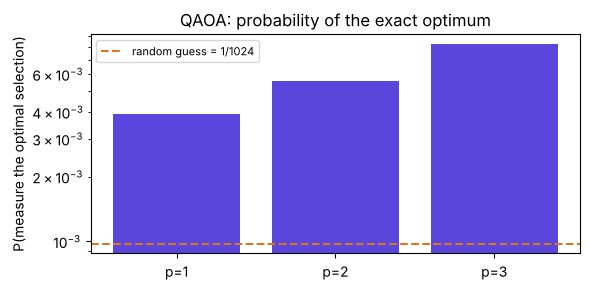

In [7]:
fig, ax = plt.subplots(figsize=(6, 3))
ps = list(qaoa_stats); ax.bar([f"p={p}" for p in ps], [qaoa_stats[p]["p_opt"] for p in ps], color="#5a45dd")
ax.axhline(1 / 2 ** n, color="#d9771f", ls="--", label=f"random guess = 1/{2 ** n}")
ax.set_ylabel("P(measure the optimal selection)"); ax.set_yscale("log"); ax.legend(fontsize=8)
ax.set_title("QAOA: probability of the exact optimum"); plt.tight_layout(); plt.show()

## Reading the results honestly

- **The formulation is the main win.** Top-3 by relevance picks the three near-duplicate error-correction passages and covers **1 of 3** aspects of the question. Solving the QUBO exactly picks one passage each on error correction, noise and mitigation: **3 of 3**. Compare the *aspects* column above.
- **Classical solvers already find that optimum** at this size: exhaustive search trivially, and simulated annealing in about a second. MMR, a greedy diversity heuristic, may or may not land on it; check its row above.
- **QAOA improves with depth when trained carefully** (each depth warm-started from the previous one): the probability of measuring the optimal selection rises from about 4× to 8× random guessing between p = 1 and p = 3. Taking the best of 100 shots, every depth found a selection covering all three aspects, and p = 2 and 3 found the exact optimum.
- **But it is not competitive here.** The per-shot probability of the optimum stays below 1%, training took minutes on a simulator, and on 10 variables the classical solvers get the same answer instantly.
- **Tuning matters.** With a redundancy weight $\lambda$ above about 1.0, the optimum starts trading a relevant passage for an off-topic one just to reduce overlap. Weights must be tuned on real retrieval benchmarks.

**Conclusion:** treat context selection as joint optimisation; that alone improves coverage here. Whether quantum solvers ever beat classical ones on this problem, at realistic candidate-pool sizes (20–100 passages) and latency budgets, is an open question and the subject of QGAI experiment EXP-014.

**Try next:** replace TF-IDF with a sentence-embedding model; use a token budget instead of exactly K passages; scale the pool to 20 candidates and compare simulated annealing, QAOA depth and wall-clock time.